In [ ]:
!pip install transformers datasets accelerate scikit-learn pandas torch


In [1]:
from google.colab import files

uploaded = files.upload()

Saving final_leakage_checked_dataset1.zip to final_leakage_checked_dataset1.zip


In [ ]:
import torch

print("PyTorch version:", torch.__version__)

if torch.cuda.is_available():
    print("GPU is available!")
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not available. Please enable GPU.")

PyTorch version: 2.14.1+cu130
GPU is available!
GPU: Tesla T4


In [3]:
from google.colab import files

uploaded = files.upload()


Saving final_leakage_checked_dataset.zip to final_leakage_checked_dataset.zip


In [4]:
import zipfile
import os

# Get the actual uploaded filename
zip_path = list(uploaded.keys())[0]

# Extract files
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("dataset")

print("Dataset extracted successfully!")
print(os.listdir("dataset"))

Dataset extracted successfully!
['test.csv', 'val.csv', 'README.txt', 'train.csv']


In [5]:
import pandas as pd

train_df = pd.read_csv("dataset/train.csv")
val_df = pd.read_csv("dataset/val.csv")
test_df = pd.read_csv("dataset/test.csv")

print("Training shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (3631, 3)
Validation shape: (727, 3)
Testing shape: (727, 3)


In [6]:
print(train_df.head())

                                                text  \
0  congrats num mobile num g videophones r yours ...   
1  i ve told him that i ve returned it that shoul...   
2                 full heat pa i have applyed oil pa   
3  that s cool he ll be here all night lemme know...   
4  then ask dad to pick up lar wan num stay until...   

                                            raw_text  label  
0  Congrats! 2 mobile 3G Videophones R yours. cal...      1  
1  I've told him that i've returned it. That shou...      0  
2             Full heat pa:-) i have applyed oil pa.      0  
3  That's cool he'll be here all night, lemme kno...      0  
4  Then Ã¼ ask dad to pick Ã¼ up lar... Ã wan 2 ...      0  


In [7]:
print(train_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3631 entries, 0 to 3630
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      3631 non-null   object
 1   raw_text  3631 non-null   object
 2   label     3631 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 85.2+ KB
None


In [8]:
print(train_df['label'].value_counts())

label
0    3209
1     422
Name: count, dtype: int64


In [9]:
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cu130
GPU available: True


In [10]:
model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("Tokenizer loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!


In [11]:
sample_text = train_df['text'][0]

tokens = tokenizer(
    sample_text,
    padding="max_length",
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

print("Original text:", sample_text)
print("Token IDs:", tokens['input_ids'])
print("Attention Mask:", tokens['attention_mask'])

Original text: congrats num mobile num g videophones r yours call num now videochat wid your mates play java games dload polyph music noline rentl
Token IDs: tensor([[  101, 26478,  8609,  2015, 16371,  2213,  4684, 16371,  2213,  1043,
          2678, 19093,  1054,  6737,  2655, 16371,  2213,  2085,  2678,  7507,
          2102, 15536,  2094,  2115, 14711,  2377,  9262,  2399, 21469, 10441,
          2094, 26572,  8458,  2189,  2053,  4179,  9278,  2140,   102,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,  

In [12]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

In [13]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(train_df[["text", "label"]])
val_dataset = Dataset.from_pandas(val_df[["text", "label"]])
test_dataset = Dataset.from_pandas(test_df[["text", "label"]])

print(train_dataset)

Dataset({
    features: ['text', 'label'],
    num_rows: 3631
})


In [14]:
train_dataset = train_dataset.map(
    tokenize_function,
    batched=True
)

val_dataset = val_dataset.map(
    tokenize_function,
    batched=True
)

test_dataset = test_dataset.map(
    tokenize_function,
    batched=True
)

print("All datasets tokenized successfully!")

Map:   0%|          | 0/3631 [00:00<?, ? examples/s]

Map:   0%|          | 0/727 [00:00<?, ? examples/s]

Map:   0%|          | 0/727 [00:00<?, ? examples/s]

All datasets tokenized successfully!


In [15]:
train_dataset = train_dataset.rename_column("label", "labels")
val_dataset = val_dataset.rename_column("label", "labels")
test_dataset = test_dataset.rename_column("label", "labels")

print(train_dataset)

Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 3631
})


In [ ]:
from transformers import AutoTokenizer

model_name = "distilbert/distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully!


In [16]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [17]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)

print("Using device:", device)

Using device: cuda


In [18]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=-1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [20]:
import transformers
print(transformers.__version__)

5.22.1


In [21]:
from transformers import TrainingArguments, Trainer

training_args = TrainingArguments(
    output_dir="./spam_detection_model",

    num_train_epochs=3,

    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,

    learning_rate=2e-5,

    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",

    logging_steps=50,

    report_to="none"
)

print("Training configuration completed!")

Training configuration completed!


In [22]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    compute_metrics=compute_metrics
)

print("Trainer created successfully!")

Trainer created successfully!


In [23]:
train_result = trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.067228,0.065249,0.986245,0.941176,0.941176,0.941176
2,0.028471,0.069785,0.986245,0.951807,0.929412,0.940476
3,0.017802,0.080463,0.982118,0.909091,0.941176,0.924855


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
sample_message = "Congratulations! You have won a free prize."

tokens = tokenizer(sample_message)

print(tokens)

{'input_ids': [101, 23156, 999, 2017, 2031, 2180, 1037, 2489, 3396, 1012, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [24]:
test_results = trainer.evaluate(test_dataset)

print("\nFINAL TEST RESULTS")

for key, value in test_results.items():
    print(f"{key}: {value:.4f}")

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.017802,0.069927,3,0.982118,0.950000,0.894118,0.921212



FINAL TEST RESULTS
eval_loss: 0.0699
eval_accuracy: 0.9821
eval_precision: 0.9500
eval_recall: 0.8941
eval_f1: 0.9212


In [26]:
import os

model_path = "./final_distilbert_spam_model"

trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)

print("Model and tokenizer saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and tokenizer saved successfully!


In [27]:
import shutil

shutil.make_archive(
    "final_distilbert_spam_model",
    "zip",
    model_path
)

from google.colab import files

files.download("final_distilbert_spam_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
def predict_spam(message):

    inputs = tokenizer(
        message,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    model.eval()

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)

    prediction = torch.argmax(probabilities, dim=1).item()

    confidence = probabilities[0][prediction].item() * 100

    result = "SPAM" if prediction == 1 else "HAM"

    print("Message:", message)
    print("Prediction:", result)
    print(f"Confidence: {confidence:.2f}%")

In [29]:
predict_spam("Congratulations! You won a free iPhone. Click here to claim your prize!")

Message: Congratulations! You won a free iPhone. Click here to claim your prize!
Prediction: SPAM
Confidence: 64.60%


In [30]:
predict_spam("Hey, are you coming to college tomorrow?")

Message: Hey, are you coming to college tomorrow?
Prediction: HAM
Confidence: 99.66%


In [31]:
model_path = "./final_distilbert_spam_model"

trainer.save_model(model_path)
tokenizer.save_pretrained(model_path)

print("Model saved successfully!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!


In [32]:
import shutil
from google.colab import files

shutil.make_archive(
    "final_distilbert_spam_model",
    "zip",
    model_path
)

files.download("final_distilbert_spam_model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import torch

def predict_spam(message):

    inputs = tokenizer(
        message,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    trainer.model.eval()

    with torch.no_grad():
        outputs = trainer.model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=1)

    prediction = torch.argmax(probabilities, dim=1).item()

    confidence = probabilities[0][prediction].item() * 100

    result = "SPAM" if prediction == 1 else "HAM"

    print("Message:", message)
    print("Prediction:", result)
    print(f"Confidence: {confidence:.2f}%")

In [34]:
predict_spam(
    "Congratulations! You won a free iPhone. Click here to claim your prize!"
)

Message: Congratulations! You won a free iPhone. Click here to claim your prize!
Prediction: SPAM
Confidence: 64.60%


In [35]:
predict_spam(
    "Hey, are you coming to college tomorrow?"
)

Message: Hey, are you coming to college tomorrow?
Prediction: HAM
Confidence: 99.66%


In [36]:
predict_spam(
    "Mom, I will reach home by 6 pm. See you soon."
)

Message: Mom, I will reach home by 6 pm. See you soon.
Prediction: HAM
Confidence: 99.67%


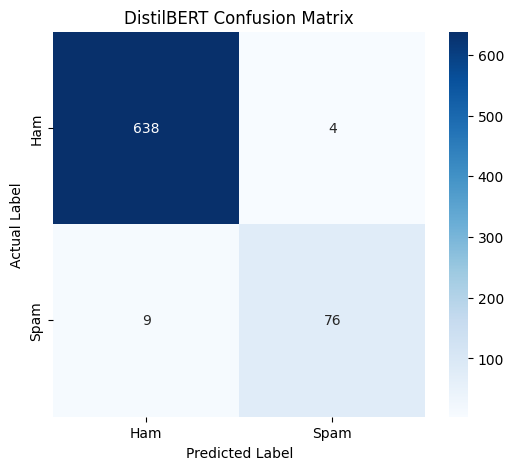

              precision    recall  f1-score   support

         Ham       0.99      0.99      0.99       642
        Spam       0.95      0.89      0.92        85

    accuracy                           0.98       727
   macro avg       0.97      0.94      0.96       727
weighted avg       0.98      0.98      0.98       727



In [25]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

predictions = trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DistilBERT Confusion Matrix")

plt.show()

print(classification_report(
    y_true,
    y_pred,
    target_names=["Ham", "Spam"]
))

In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully!")

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased",
    num_labels=2
)

print("DistilBERT model loaded successfully!")


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully!


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert/distilbert-base-uncased"
)

print("Tokenizer loaded successfully!")

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded successfully!


In [ ]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.to(device)

inputs = tokenizer(
    "Congratulations! You won a free prize.",
    return_tensors="pt"
)

inputs = {key: value.to(device) for key, value in inputs.items()}

with torch.no_grad():
    outputs = model(**inputs)

print("Model is working!")
print("Device:", device)
print("Output shape:", outputs.logits.shape)

Model is working!
Device: cuda
Output shape: torch.Size([1, 2])
